# Reduksi Dimensi PCA, K-Means Clustering, dan Klasifikasi Sawah dan Non-Sawah Menggunakan Citra Sentinel-2A dengan Random Forest

Notebook ini memuat dua pekerjaan. Pekerjaan pertama adalah **K-Means clustering** pada fitur hasil ekstraksi **TSFEL** data polutan udara (CO, NO2, SO2) di 37 kecamatan Jawa Timur setelah reduksi dimensi **PCA** (203, 74, dan 37 dimensi), pada data versi **Polynomial** dan **Linear Regression**. Pekerjaan kedua adalah klasifikasi penutup lahan dua kelas, yaitu **sawah** (kelas 1) dan **non-sawah** (kelas 0) di **Kecamatan Pilangkenceng, Kabupaten Madiun**, menggunakan citra **Sentinel-2A Level-2A** dan algoritma **Random Forest** (*scikit-learn*). Data sampel klasifikasi berupa poligon hasil digitasi di QGIS, masing-masing 50 poligon untuk setiap kelas.

Tahapan yang dilakukan adalah sebagai berikut:

1. Persiapan lingkungan, pustaka, dan data.

2. Penetapan parameter clustering.

3. Pembacaan data dan standarisasi fitur.

4. Pencarian jumlah *cluster* terbaik (*Elbow* dan *Silhouette*).

5. Eksperimen PCA 3 level dimensi dan K-Means pada data Polynomial dan Linear Regression.

6. Pembuatan peta *cluster* kecamatan.

7. Persiapan data sampel sawah dan non-sawah.

8. Penetapan parameter klasifikasi.

9. Pembacaan poligon sampel dan penentuan area kajian, disertai peta batas administratif dan peta interaktif lokasi sampel.

10. Penyediaan citra Sentinel-2A (menggunakan citra yang telah tersedia atau mengunduh dari Copernicus).

11. Pembacaan citra dan pembentukan fitur (band dan indeks spektral).

12. Rasterisasi poligon sampel.

13. Pembagian data latih dan data uji per poligon.

14. Pelatihan model dan evaluasi.

15. Klasifikasi seluruh citra dan penghitungan luas.

16. Penyimpanan keluaran (GeoTIFF, peta, dan ringkasan evaluasi).

## 1. Persiapan Lingkungan dan Data

Sel berikut memasang pustaka yang belum tersedia (`folium`, `geopy`, `rasterio`, dan `geopandas`) serta memuat seluruh pustaka yang digunakan.

In [1]:
import subprocess, sys

try:
    import folium, geopy, rasterio, geopandas
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "folium", "geopy", "rasterio", "geopandas"])

**Penjelasan kode:** Kode ini memeriksa ketersediaan `folium`, `geopy`, `rasterio`, dan `geopandas`. Apabila ada yang belum terpasang (misalnya pada Google Colab), keempat pustaka tersebut dipasang secara otomatis menggunakan `pip`.

In [2]:
import datetime as dt
import io
import math
import os
import time
import zipfile
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests
from folium.plugins import Fullscreen
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio import features
from rasterio.warp import transform_bounds, transform_geom
from shapely.geometry import mapping, shape
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix, silhouette_score)
from sklearn.preprocessing import StandardScaler

**Penjelasan kode:** Kode ini mengimpor pustaka untuk pengolahan data tabel (`numpy`, `pandas`), reduksi dimensi dan *clustering* (`PCA`, `KMeans`, `StandardScaler`, `silhouette_score`), data vektor dan raster (`geopandas`, `shapely`, `rasterio`), visualisasi statis (`matplotlib`) dan interaktif (`folium`), permintaan ke layanan Copernicus dan penyedia batas administratif (`requests`), serta model dan metrik evaluasi klasifikasi (`scikit-learn`).

In [3]:
IN_COLAB = "google.colab" in sys.modules
BASE_DIR = Path("/content") if IN_COLAB else Path.cwd()

FILE_CSV = {
    "polynomial": BASE_DIR / "ekstraksi_fitur_polynomial.csv",
    "linear": BASE_DIR / "ekstraksi_fitur_linear.csv",
}


def cari_zip(sertakan, kecualikan=None):
    # Cari berkas ZIP di folder kerja berdasarkan kata pada namanya
    for p in sorted(BASE_DIR.glob("*.zip")):
        nama = p.name.lower()
        if sertakan in nama and not (kecualikan and kecualikan in nama):
            return p
    return None


# Di Google Colab: unggah ekstraksi_fitur_polynomial.csv, ekstraksi_fitur_linear.csv,
# ZIP shapefile sawah dan non-sawah (mis. "data sawah.zip" dan "data non sawah.zip"),
# serta (opsional) titik_koordinat_kecamatan.csv dan sentinel2a_aoi.tif
perlu = (not all(p.exists() for p in FILE_CSV.values())
         or cari_zip("sawah", "non") is None or cari_zip("non") is None)
if IN_COLAB and perlu:
    from google.colab import files
    print("Unggah 2 CSV ekstraksi fitur, ZIP shapefile sawah dan non-sawah, "
          "dan (opsional) titik_koordinat_kecamatan.csv / sentinel2a_aoi.tif")
    files.upload()

for tag, berkas in FILE_CSV.items():
    if not berkas.exists():
        raise FileNotFoundError(f"{berkas.name} tidak ditemukan di {BASE_DIR}")

print("Folder kerja:", BASE_DIR)
print("CSV ekstraksi fitur:", sorted(p.name for p in FILE_CSV.values()))
print("ZIP sawah    :", cari_zip("sawah", "non"))
print("ZIP non-sawah:", cari_zip("non"))

Folder kerja: /content
CSV ekstraksi fitur: ['ekstraksi_fitur_linear.csv', 'ekstraksi_fitur_polynomial.csv']
ZIP sawah    : /content/data sawah.zip
ZIP non-sawah: /content/data non sawah.zip


**Penjelasan kode:** Kode ini menentukan folder kerja (`/content` pada Google Colab atau folder aktif pada komputer lokal), mendaftarkan dua berkas CSV hasil ekstraksi fitur, dan menyediakan fungsi `cari_zip` untuk menemukan ZIP shapefile sawah dan non-sawah berdasarkan kata pada namanya. Pada Google Colab, berkas yang belum ada diminta untuk diunggah, lalu keberadaan kedua CSV diperiksa.

## 2. Parameter

Pengaturan eksperimen clustering dikumpulkan pada satu sel agar mudah diubah. Level reduksi dimensi yang diuji adalah **203, 74, dan 37**. Kotak pembatas `JATIM_BBOX` dipakai untuk menyaring titik hasil *geocoding* yang jatuh di luar Jawa Timur. Berkas `titik_koordinat_kecamatan.csv` dipakai ulang apabila sudah ada.

In [4]:
DIM_LEVELS = [203, 74, 37]
SEED = 42
COORD_CSV = BASE_DIR / "titik_koordinat_kecamatan.csv"
JATIM_BBOX = (-8.9, -5.9, 110.8, 114.8)    # (lat_min, lat_max, lon_min, lon_max)

CHART_DIR = BASE_DIR / "_static" / "charts" / "clustering_exp"
STATIC_DIR = BASE_DIR / "_static"
STATIC_DIR.mkdir(parents=True, exist_ok=True)

HEX_COLORS = ["#1F6F78", "#C97B2E", "#7A4B9E", "#B23A48", "#4F772D", "#3D5A80"]

**Penjelasan kode:** Kode ini menetapkan tiga level dimensi PCA, *random seed* (42), lokasi berkas koordinat, kotak pembatas Jawa Timur, folder keluaran grafik dan peta, serta warna untuk setiap *cluster*.

## 3. Pembacaan Data dan Standarisasi Fitur

Data dibaca dari berkas CSV. Penulisan nama kecamatan dirapikan (misalnya `"Jabon , Sidoarjo"` menjadi `"Jabon, Sidoarjo"`). Kolom `id` tidak dihitung sebagai fitur, sedangkan kolom teks (`nama`, `daerah`) otomatis dikeluarkan karena bukan angka. Nilai kosong diisi dengan rata-rata kolom, lalu seluruh fitur distandarisasi (*z-score*) agar fitur berskala besar tidak mendominasi jarak Euclidean pada PCA dan K-Means.

$$z=\frac{x-\mu}{\sigma}$$

In [5]:
def muat_data(path):
    df = pd.read_csv(path)
    # rapikan penulisan nama kecamatan (mis. "Jabon , Sidoarjo" -> "Jabon, Sidoarjo")
    df["daerah"] = (df["daerah"].astype(str)
                    .str.replace(r"\s+,", ",", regex=True)
                    .str.replace(r"\s{2,}", " ", regex=True)
                    .str.strip())
    feature_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                    if c.lower() != "id"]          # 'id' bukan fitur, jangan ikut dihitung
    X = df[feature_cols].copy()
    X = X.fillna(X.mean())
    X_scaled = StandardScaler().fit_transform(X)
    return df, feature_cols, X_scaled

**Penjelasan kode:** Fungsi `muat_data` membaca CSV, merapikan nama kecamatan, memilih kolom numerik selain `id` sebagai fitur, mengisi nilai kosong dengan rata-rata kolom, dan menstandarisasi fitur dengan `StandardScaler`. Fungsi mengembalikan tabel asli, daftar kolom fitur, dan matriks fitur yang sudah distandarisasi.

## 4. Pencarian Jumlah Cluster Terbaik

Jumlah *cluster* ditentukan dengan dua cara. **Elbow Method** melihat penurunan *inertia* (WCSS) saat k bertambah, sedangkan **Silhouette Score** mengukur seberapa baik setiap titik cocok dengan *cluster*-nya dibandingkan *cluster* terdekat lain. Nilai k terbaik dipilih dari Silhouette Score tertinggi.

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}}$$

dengan $a(i)$ adalah rata-rata jarak titik $i$ ke titik lain dalam *cluster* yang sama dan $b(i)$ adalah rata-rata jarak ke *cluster* tetangga terdekat.

In [6]:
def analisis_cluster(data, label_dim, chart_dir, k_range=range(2, 11)):
    inertias, silhouettes = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
        labels = km.fit_predict(data)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(data, labels))
    best_k = list(k_range)[int(np.argmax(silhouettes))]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    axes[0].plot(list(k_range), inertias, marker="o", color="#1F6F78")
    axes[0].set_xlabel("Jumlah Cluster (k)"); axes[0].set_ylabel("Inertia (WCSS)")
    axes[0].set_title(f"Elbow Method - Dimensi {label_dim}")
    axes[1].plot(list(k_range), silhouettes, marker="o", color="#C97B2E")
    axes[1].axvline(best_k, color="red", linestyle="--", alpha=0.5)
    axes[1].set_xlabel("Jumlah Cluster (k)"); axes[1].set_ylabel("Silhouette Score")
    axes[1].set_title(f"Silhouette Score - Dimensi {label_dim} (terbaik: k={best_k})")
    fig.tight_layout()
    fname = chart_dir / f"elbow-silhouette-dim{label_dim}.png"
    fig.savefig(fname, dpi=150)
    plt.close(fig)

    print(f"[Dimensi {label_dim}] k terbaik = {best_k} "
          f"(silhouette = {max(silhouettes):.4f}) | grafik: {fname.name}")
    return best_k, silhouettes

**Penjelasan kode:** Fungsi `analisis_cluster` menjalankan K-Means untuk setiap k dari 2 sampai 10, menghitung *inertia* dan Silhouette Score, memilih k dengan Silhouette tertinggi, lalu menyimpan grafik *Elbow* dan *Silhouette* ke folder keluaran. Hasil yang dikembalikan adalah `best_k` dan daftar skor Silhouette.

## 5. Eksperimen PCA 3 Level Dimensi dan K-Means

Untuk setiap level dimensi (203, 74, 37), data hasil standarisasi direduksi dengan PCA, kemudian K-Means dijalankan dengan k terbaik hasil Silhouette. Jumlah komponen PCA dibatasi secara matematis oleh $\min(n_{sampel}-1,\;n_{fitur})$. Dengan **37 sampel**, jumlah komponen maksimum adalah **36**, sehingga target 203 dan 74 dimensi otomatis dipotong menjadi 36 komponen. Itulah sebabnya ketiga level menghasilkan nilai yang sama persis.

In [7]:
def jalankan_eksperimen(tag):
    chart_dir = CHART_DIR / tag
    chart_dir.mkdir(parents=True, exist_ok=True)

    df, feature_cols, X_scaled = muat_data(FILE_CSV[tag])
    n_samples, n_features = X_scaled.shape
    print(f"Dataset: {n_samples} kecamatan x {n_features} fitur")
    print(f"Kolom yang di-exclude (bukan fitur): {[c for c in df.columns if c not in feature_cols]}")

    hasil = df[[c for c in ("nama", "daerah") if c in df.columns]].copy()
    ringkasan = []

    for target_dim in DIM_LEVELS:
        n_comp = min(target_dim, n_samples - 1, n_features)
        if n_comp != target_dim:
            print(f"\nCatatan: target dimensi {target_dim} > batas matematis "
                  f"({n_samples - 1} sampel-1 atau {n_features} fitur), dipakai {n_comp} komponen.")

        pca = PCA(n_components=n_comp)
        X_pca = pca.fit_transform(X_scaled)
        var_explained = np.sum(pca.explained_variance_ratio_) * 100
        print(f"\n=== Dimensi target {target_dim} (dipakai {n_comp} komponen), "
              f"varians dijelaskan: {var_explained:.2f}% ===")

        best_k, silhouettes = analisis_cluster(X_pca, target_dim, chart_dir)

        km_final = KMeans(n_clusters=best_k, random_state=SEED, n_init=10)
        labels_final = km_final.fit_predict(X_pca)
        hasil[f"cluster_dim{target_dim}"] = labels_final

        # scatter plot PC1 vs PC2 untuk level dimensi ini
        fig, ax = plt.subplots(figsize=(8, 6))
        for c in range(best_k):
            mask = labels_final == c
            ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=80,
                       color=HEX_COLORS[c % len(HEX_COLORS)],
                       edgecolor="white", linewidth=0.8,
                       label=f"Cluster {c} ({mask.sum()})")
        ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
        ax.set_title(f"Scatter PCA - Dimensi {target_dim}, k={best_k}")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(chart_dir / f"scatter-dim{target_dim}.png", dpi=150)
        plt.close(fig)

        ringkasan.append({
            "Target Dimensi": target_dim,
            "Komponen Dipakai": n_comp,
            "Varians Dijelaskan (%)": round(var_explained, 2),
            "k Terbaik": best_k,
            "Silhouette Score": round(max(silhouettes), 4),
        })

    out_csv = f"hasil_clustering_3level_{tag}.csv"
    hasil.to_csv(BASE_DIR / out_csv, index=False)
    print(f"\nTersimpan: {out_csv}")

    ringkasan_df = pd.DataFrame(ringkasan)
    print("\n" + "=" * 70)
    print("RINGKASAN EKSPERIMEN 3 LEVEL DIMENSI")
    print("=" * 70)
    print(ringkasan_df.to_string(index=False))
    print("\n--- Tabel markdown (copy ke laporan) ---")
    print("| " + " | ".join(ringkasan_df.columns) + " |")
    print("|" + "|".join(["---"] * len(ringkasan_df.columns)) + "|")
    for row in ringkasan_df.astype(object).itertuples(index=False):
        print("| " + " | ".join(str(v) for v in row) + " |")

    return df, hasil

**Penjelasan kode:** Fungsi `jalankan_eksperimen` memuat data satu versi (`polynomial` atau `linear`), lalu untuk setiap level dimensi melakukan PCA, mencari k terbaik, menjalankan K-Means akhir, menyimpan label *cluster* ke tabel `hasil`, dan membuat *scatter plot* PC1 vs PC2. Setelah semua level selesai, label disimpan ke `hasil_clustering_3level_<versi>.csv` dan ringkasan (komponen yang dipakai, varians dijelaskan, k terbaik, Silhouette Score) dicetak, termasuk dalam format tabel *markdown* yang siap disalin ke laporan.

### 5.1 Data Versi Polynomial

In [8]:
df_poly, hasil_poly = jalankan_eksperimen("polynomial")

Dataset: 37 kecamatan x 204 fitur
Kolom yang di-exclude (bukan fitur): ['id', 'nama', 'daerah']

Catatan: target dimensi 203 > batas matematis (36 sampel-1 atau 204 fitur), dipakai 36 komponen.

=== Dimensi target 203 (dipakai 36 komponen), varians dijelaskan: 100.00% ===
[Dimensi 203] k terbaik = 2 (silhouette = 0.5375) | grafik: elbow-silhouette-dim203.png

Catatan: target dimensi 74 > batas matematis (36 sampel-1 atau 204 fitur), dipakai 36 komponen.

=== Dimensi target 74 (dipakai 36 komponen), varians dijelaskan: 100.00% ===
[Dimensi 74] k terbaik = 2 (silhouette = 0.5375) | grafik: elbow-silhouette-dim74.png

Catatan: target dimensi 37 > batas matematis (36 sampel-1 atau 204 fitur), dipakai 36 komponen.

=== Dimensi target 37 (dipakai 36 komponen), varians dijelaskan: 100.00% ===
[Dimensi 37] k terbaik = 2 (silhouette = 0.5375) | grafik: elbow-silhouette-dim37.png

Tersimpan: hasil_clustering_3level_polynomial.csv

RINGKASAN EKSPERIMEN 3 LEVEL DIMENSI
 Target Dimensi  Komponen Di

**Penjelasan kode:** Eksperimen dijalankan pada data Polynomial (37 kecamatan, 204 fitur). Ketiga level dimensi menghasilkan 36 komponen dengan varians dijelaskan 100%, k terbaik = 2, dan Silhouette Score = **0,5375**. Keluaran di atas adalah hasil eksekusi yang sudah Anda jalankan sebelumnya.

### 5.2 Data Versi Linear Regression

In [9]:
df_linear, hasil_linear = jalankan_eksperimen("linear")

Dataset: 37 kecamatan x 204 fitur
Kolom yang di-exclude (bukan fitur): ['id', 'nama', 'daerah']

Catatan: target dimensi 203 > batas matematis (36 sampel-1 atau 204 fitur), dipakai 36 komponen.

=== Dimensi target 203 (dipakai 36 komponen), varians dijelaskan: 100.00% ===
[Dimensi 203] k terbaik = 2 (silhouette = 0.4909) | grafik: elbow-silhouette-dim203.png

Catatan: target dimensi 74 > batas matematis (36 sampel-1 atau 204 fitur), dipakai 36 komponen.

=== Dimensi target 74 (dipakai 36 komponen), varians dijelaskan: 100.00% ===
[Dimensi 74] k terbaik = 2 (silhouette = 0.4909) | grafik: elbow-silhouette-dim74.png

Catatan: target dimensi 37 > batas matematis (36 sampel-1 atau 204 fitur), dipakai 36 komponen.

=== Dimensi target 37 (dipakai 36 komponen), varians dijelaskan: 100.00% ===
[Dimensi 37] k terbaik = 2 (silhouette = 0.4909) | grafik: elbow-silhouette-dim37.png

Tersimpan: hasil_clustering_3level_linear.csv

RINGKASAN EKSPERIMEN 3 LEVEL DIMENSI
 Target Dimensi  Komponen Dipaka

**Penjelasan kode:** Eksperimen yang sama dijalankan pada data Linear Regression. Hasilnya juga 36 komponen dengan varians dijelaskan 100% dan k terbaik = 2, tetapi Silhouette Score lebih rendah, yaitu **0,4909**, sehingga pengelompokan pada data Polynomial lebih terpisah dibanding data Linear Regression.

## 6. Peta Cluster Kecamatan

Setiap kecamatan diberi koordinat melalui *geocoding* (**Nominatim/OpenStreetMap**, butuh internet). Hasilnya disimpan ke `titik_koordinat_kecamatan.csv` sehingga eksekusi berikutnya tidak perlu *geocoding* ulang. Koordinat yang kosong atau tampak janggal (misalnya Nunukan, Tikala-Manado, dan Warudoyong-Sukabumi yang berada di luar Jawa Timur) perlu diperiksa dan diperbaiki manual pada berkas tersebut. Titik di luar Jawa Timur tidak ditampilkan pada peta.

In [10]:
def short_name(daerah):
    return str(daerah).split(",")[0].strip()


def buat_peta_cluster(tag, df, hasil):
    chart_dir = CHART_DIR / tag
    daerah_unik = df["daerah"].astype(str).str.strip().unique().tolist()

    if COORD_CSV.exists():
        coords = pd.read_csv(COORD_CSV)
        print(f"\nMemakai koordinat dari {COORD_CSV.name}")
    else:
        coords = pd.DataFrame(columns=["daerah", "lat", "lon"])

    todo = [d for d in daerah_unik if d not in coords["daerah"].astype(str).str.strip().values]
    if todo:
        from geopy.geocoders import Nominatim
        geolocator = Nominatim(user_agent="psd-tugas-pca3level")
        rows = []
        print(f"Geocoding {len(todo)} kecamatan yang belum punya koordinat (butuh internet)...")
        for d in todo:
            lat = lon = np.nan
            for q in [f"Kecamatan {d}, Indonesia", f"{d}, Indonesia"]:
                try:
                    loc = geolocator.geocode(q, timeout=10)
                except Exception:
                    loc = None
                time.sleep(1.1)
                if loc:
                    lat, lon = loc.latitude, loc.longitude
                    break
            print(f"  {d:35s} -> {lat}, {lon}")
            rows.append({"daerah": d, "lat": lat, "lon": lon})
        coords = pd.concat([coords, pd.DataFrame(rows)], ignore_index=True)
        coords.to_csv(COORD_CSV, index=False)
        print(f"Tersimpan: {COORD_CSV.name} <- cek & perbaiki koordinat yang aneh/kosong, lalu jalankan ulang")

    kosong = coords[coords["lat"].isna()]["daerah"].tolist()
    if kosong:
        print(f"PERINGATAN: koordinat kosong untuk {kosong}. Isi manual lat/lon di {COORD_CSV.name}.")

    base = hasil.copy()
    base["daerah"] = base["daerah"].astype(str).str.strip()
    base = base.merge(coords, on="daerah", how="left")
    # geser sedikit kecamatan yang namanya sama agar titiknya tidak menumpuk
    dup_idx = base.groupby("daerah").cumcount()
    base["lat"] = base["lat"] + dup_idx * 0.004
    base["lon"] = base["lon"] + dup_idx * 0.004

    peta = {}
    for target_dim in DIM_LEVELS:
        col = f"cluster_dim{target_dim}"
        valid = base.dropna(subset=["lat", "lon", col])
        lat_min, lat_max, lon_min, lon_max = JATIM_BBOX
        in_jatim = valid["lat"].between(lat_min, lat_max) & valid["lon"].between(lon_min, lon_max)
        focus = valid[in_jatim] if in_jatim.any() else valid
        k_dim = int(valid[col].max()) + 1

        # ---- PNG statis ----
        fig, ax = plt.subplots(figsize=(9, 7))
        for c in range(k_dim):
            sub = focus[focus[col] == c]
            ax.scatter(sub["lon"], sub["lat"], s=100,
                       color=HEX_COLORS[c % len(HEX_COLORS)],
                       edgecolor="white", linewidth=0.8,
                       label=f"Cluster {c} ({len(sub)})")
        for _, r in focus.iterrows():
            ax.annotate(short_name(r["daerah"]), (r["lon"], r["lat"]),
                        fontsize=6.5, alpha=0.75, xytext=(5, 4), textcoords="offset points")
        ax.set_xlim(focus["lon"].min() - 0.15, focus["lon"].max() + 0.15)
        ax.set_ylim(focus["lat"].min() - 0.15, focus["lat"].max() + 0.15)
        ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
        ax.set_title(f"Peta Cluster - Reduksi Dimensi {target_dim}")
        ax.set_aspect("equal", adjustable="box")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(chart_dir / f"peta-dim{target_dim}.png", dpi=150)
        plt.close(fig)

        # ---- HTML interaktif ----
        m = folium.Map(location=[focus["lat"].mean(), focus["lon"].mean()],
                       zoom_start=8, tiles="OpenStreetMap")
        for _, r in focus.iterrows():
            color = HEX_COLORS[int(r[col]) % len(HEX_COLORS)]
            folium.CircleMarker(
                location=[r["lat"], r["lon"]], radius=9, color="white", weight=1.5,
                fill=True, fill_color=color, fill_opacity=0.9,
                tooltip=f"{r['daerah']} - Cluster {int(r[col])}",
                popup=f"<b>{r['daerah']}</b><br>Dimensi {target_dim}, Cluster {int(r[col])}",
            ).add_to(m)
        m.fit_bounds([[focus["lat"].min(), focus["lon"].min()],
                      [focus["lat"].max(), focus["lon"].max()]])
        legend_items = "".join(
            f'<div><span style="background:{HEX_COLORS[c % len(HEX_COLORS)]};'
            f'display:inline-block;width:12px;height:12px;border-radius:50%;'
            f'margin-right:6px;"></span>Cluster {c}</div>' for c in range(k_dim))
        legend_html = (
            '<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;'
            'padding:10px 14px;border:1px solid #bbb;border-radius:6px;font-size:13px;'
            f'font-family:sans-serif;"><b>Dimensi {target_dim} (k={k_dim})</b>{legend_items}</div>')
        m.get_root().html.add_child(folium.Element(legend_html))
        m.save(str(STATIC_DIR / f"peta-cluster-{tag}-dim{target_dim}.html"))
        print(f"Tersimpan: peta-dim{target_dim}.png dan peta-cluster-{tag}-dim{target_dim}.html")
        peta[target_dim] = m

    print("\nSelesai eksperimen 3 level dimensi!")
    return peta

**Penjelasan kode:** Fungsi `buat_peta_cluster` membaca koordinat dari `titik_koordinat_kecamatan.csv` (atau melakukan *geocoding* hanya untuk kecamatan yang belum punya koordinat), memberi peringatan bila ada koordinat kosong, menggabungkan koordinat dengan label *cluster*, lalu untuk setiap level dimensi membuat peta statis (`peta-dim*.png`) dan peta interaktif (`peta-cluster-<versi>-dim*.html`) dengan *tooltip*, *popup*, dan legenda. Titik di luar kotak pembatas Jawa Timur disaring.

### 6.1 Peta Cluster Data Polynomial

In [11]:
peta_poly = buat_peta_cluster("polynomial", df_poly, hasil_poly)

Geocoding 35 kecamatan yang belum punya koordinat (butuh internet)...
  Baron Nganjuk                       -> -7.6071174, 112.0510318
  Nunukan                             -> 4.1344651, 117.6451682
  Sreseh, Sampang                     -> -7.2190022, 113.1328604
  Manyar, Gresik                      -> -7.2347721, 112.564431
  Kamal, Bangkalan                    -> -7.1702821, 112.7288563
  Kedungpring Lamongan                -> -7.1843952, 112.1982965
  Gresik Kota, Gresik                 -> -7.206313, 112.6386912
  Waru, Pamekasan                     -> -6.9418166, 113.5515118
  Paciran, Lamongan                   -> -6.8703484, 112.339679
  Kertosono, Nganjuk                  -> -7.6071174, 112.0510318
  Jabon, Sidoarjo                     -> -7.5351067, 112.810693
  Menganti, Gresik                    -> -7.3028931, 112.5828799
  Bandung - Jogoroto, Jombang         -> nan, nan
  Banyu Ajuh, Perumnas, Kamal         -> nan, nan
  Widang, Tuban                       -> -7.085116, 112

/tmp/ipykernel_1067/3476388279.py:34: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  coords = pd.concat([coords, pd.DataFrame(rows)], ignore_index=True)


Tersimpan: peta-dim203.png dan peta-cluster-polynomial-dim203.html
Tersimpan: peta-dim74.png dan peta-cluster-polynomial-dim74.html
Tersimpan: peta-dim37.png dan peta-cluster-polynomial-dim37.html

Selesai eksperimen 3 level dimensi!


**Penjelasan kode:** Peta dibuat untuk ketiga level dimensi pada data Polynomial. Tiga kecamatan belum punya koordinat (Bandung-Jogoroto, Banyu Ajuh-Perumnas-Kamal, dan Kalianget), sehingga tidak muncul di peta sampai lat/lon-nya diisi manual pada `titik_koordinat_kecamatan.csv`.

### 6.2 Peta Cluster Data Linear Regression

In [12]:
peta_linear = buat_peta_cluster("linear", df_linear, hasil_linear)


Memakai koordinat dari titik_koordinat_kecamatan.csv
PERINGATAN: koordinat kosong untuk ['Bandung - Jogoroto, Jombang', 'Banyu Ajuh, Perumnas, Kamal', 'Kec. Kalianget, Sumenep']. Isi manual lat/lon di titik_koordinat_kecamatan.csv.
Tersimpan: peta-dim203.png dan peta-cluster-linear-dim203.html
Tersimpan: peta-dim74.png dan peta-cluster-linear-dim74.html
Tersimpan: peta-dim37.png dan peta-cluster-linear-dim37.html

Selesai eksperimen 3 level dimensi!


**Penjelasan kode:** Langkah yang sama diterapkan pada data Linear Regression. Warna dan nomor *cluster* dapat berbeda dengan data Polynomial karena penomoran label K-Means bersifat acak, sehingga yang dibandingkan adalah pola pengelompokannya.

## 7. Persiapan Data Sampel

Berkas ZIP sawah dan non-sawah (masing-masing berisi satu set *shapefile* `.shp`, `.shx`, `.dbf`, `.prj`) diekstrak ke folder `datasawah50/` dan `nonsawah/`.

In [13]:
ZIP_SAWAH = cari_zip("sawah", "non")
ZIP_NONSAWAH = cari_zip("non")

for nama, berkas in (("ZIP sawah", ZIP_SAWAH), ("ZIP non-sawah", ZIP_NONSAWAH)):
    if berkas is None:
        raise FileNotFoundError(f"{nama} tidak ditemukan di {BASE_DIR}. "
                                "Letakkan berkas ZIP shapefile (mis. 'data sawah.zip' dan "
                                "'data non sawah.zip') di folder kerja.")

for berkas, folder in ((ZIP_SAWAH, "datasawah50"), (ZIP_NONSAWAH, "nonsawah")):
    with zipfile.ZipFile(berkas) as zf:
        zf.extractall(BASE_DIR / folder)

print("Folder kerja:", BASE_DIR)
print("Sawah    :", sorted(p.name for p in (BASE_DIR / "datasawah50").iterdir()))
print("Non-sawah:", sorted(p.name for p in (BASE_DIR / "nonsawah").iterdir()))

Folder kerja: /content
Sawah    : ['input.dbf', 'input.prj', 'input.shp', 'input.shx']
Non-sawah: ['input.dbf', 'input.prj', 'input.shp', 'input.shx']


**Penjelasan kode:** Kode ini mencari kedua berkas ZIP, menghentikan proses dengan pesan jelas apabila salah satunya tidak ada, lalu mengekstraknya ke folder `datasawah50/` dan `nonsawah/`. Daftar berkas yang dihasilkan dicetak untuk memastikan keempat komponen *shapefile* tersedia.

## 8. Parameter

Seluruh pengaturan dikumpulkan pada satu sel agar mudah diubah. Apabila berkas `sentinel2a_aoi.tif` belum tersedia di folder kerja, citra akan diunduh otomatis dari Copernicus untuk area kajian yang dihitung dari *shapefile* sampel. Apabila berkas tersebut sudah ada (misalnya diunggah manual), proses unduh dilewati kecuali `UNDUH_ULANG = True`.

In [14]:
# --- Pencarian citra (hanya dipakai bila citra diunduh) ---
UNDUH_ULANG = False            # True: unduh ulang citra dari Copernicus
START_DATE = "2026-08-01"
END_DATE = "2026-10-10"
PLATFORM_PREFIX = "S2A"        # hanya Sentinel-2A; None untuk semua satelit Sentinel-2
MAX_CLOUD = 30                 # persen awan maksimum (level tile)
MAX_TRIES = 5                  # jumlah scene terbaik yang dicoba
MIN_VALID = 0.90               # minimal fraksi piksel bebas awan
MASK_CLOUD = True              # masking awan memakai band SCL
BUFFER_M = 1500                # margin area unduhan di sekeliling sampel (meter)

# --- Sampel dan model ---
N_SAMPLE = 50                  # jumlah poligon sampel per kelas
FILE_SAWAH = sorted((BASE_DIR / "datasawah50").glob("*.shp"))[0]     # kelas 1
FILE_NONSAWAH = sorted((BASE_DIR / "nonsawah").glob("*.shp"))[0]     # kelas 0
TRAIN_FRAC = 0.7               # proporsi poligon untuk data latih
N_TREES = 200
SEED = 42

# --- Wilayah kajian ---
KEC_NAMA, KAB_NAMA, PROV_NAMA = "Pilangkenceng", "Madiun", "Jawa Timur"
WARNA = {"sawah": "#4B1D91", "non-sawah": "#F4A3A3"}   # sesuai peta QGIS (ungu = sawah, merah muda = non-sawah)

# --- Berkas ---
TIF_IN = BASE_DIR / "sentinel2a_aoi.tif"
INFO_TXT = BASE_DIR / "sentinel2a_aoi_info.txt"
OUT_TIF = BASE_DIR / "klasifikasi_sawah_s2a.tif"
OUT_PNG = BASE_DIR / "peta_klasifikasi.png"
OUT_TXT = BASE_DIR / "hasil_evaluasi.txt"

BAND_NAMES = ["B02", "B03", "B04", "B08", "B11", "B12"]

TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
CATALOG_URL = "https://sh.dataspace.copernicus.eu/api/v1/catalog/1.0.0/search"
PROCESS_URL = "https://sh.dataspace.copernicus.eu/api/v1/process"

LOG = []

def log(*args):
    s = " ".join(str(a) for a in args)
    print(s)
    LOG.append(s)

**Penjelasan kode:** Kode ini menetapkan parameter pencarian citra, jumlah sampel (50 poligon per kelas), proporsi data latih (70%), jumlah pohon Random Forest (200), *random seed* (42), nama wilayah kajian (Pilangkenceng, Madiun), warna kelas yang disamakan dengan peta QGIS, serta lokasi berkas masukan dan keluaran. Fungsi `log()` mencetak teks sekaligus menyimpannya ke daftar `LOG` yang kemudian ditulis menjadi `hasil_evaluasi.txt`.

## 9. Pembacaan Poligon Sampel dan Penentuan Area Kajian

Poligon sampel dibaca dari *shapefile*, diproyeksikan ke WGS-84 (EPSG:4326), dan dipilih secara acak sebanyak `N_SAMPLE` poligon per kelas. Kotak pembatas (*bounding box*) seluruh sampel ditambah margin `BUFFER_M` digunakan sebagai area kajian.

In [15]:
def read_samples_gdf(path, n):
    gdf = gpd.read_file(path)
    total = len(gdf)
    gdf = gdf[gdf.geometry.notna()].copy()

    if gdf.crs is None:
        log(f"PERINGATAN: {Path(path).name} tidak memiliki CRS. Diasumsikan EPSG:4326.")
    elif gdf.crs.to_epsg() != 4326:
        gdf = gdf.to_crs(epsg=4326)

    if len(gdf) > n:
        idx = np.random.default_rng(SEED).choice(len(gdf), n, replace=False)
        gdf = gdf.iloc[sorted(idx)].copy()
    elif len(gdf) < n:
        log(f"PERINGATAN: {Path(path).name} hanya berisi {total} poligon (< {n}).")

    log(f"{Path(path).parent.name}/{Path(path).name}: {total} poligon di file -> dipakai {len(gdf)}")
    return gdf.reset_index(drop=True)


def iter_xy(c):
    if isinstance(c[0], (int, float)):
        yield c[0], c[1]
    else:
        for s in c:
            yield from iter_xy(s)


gdf_sawah = read_samples_gdf(FILE_SAWAH, N_SAMPLE)
gdf_non = read_samples_gdf(FILE_NONSAWAH, N_SAMPLE)

# kolom keterangan untuk peta interaktif
gdf_sawah["kelas"], gdf_sawah["no"] = "Sawah", range(1, len(gdf_sawah) + 1)
gdf_non["kelas"], gdf_non["no"] = "Non-sawah", range(1, len(gdf_non) + 1)

geoms_sawah = [mapping(g) for g in gdf_sawah.geometry]
geoms_non = [mapping(g) for g in gdf_non.geometry]

xy = [p for g in geoms_sawah + geoms_non for p in iter_xy(g["coordinates"])]
pad = BUFFER_M / 111000.0
BBOX = (min(x for x, _ in xy) - pad, min(y for _, y in xy) - pad,
        max(x for x, _ in xy) + pad, max(y for _, y in xy) + pad)
log("BBox area (lon/lat):", tuple(round(v, 5) for v in BBOX))

datasawah50/input.shp: 50 poligon di file -> dipakai 50
nonsawah/input.shp: 50 poligon di file -> dipakai 50
BBox area (lon/lat): (111.61371, -7.49689, 111.65148, -7.46088)


**Penjelasan kode:** Fungsi `read_samples_gdf` membaca *shapefile*, membuang fitur tanpa geometri, mengubah sistem koordinat ke EPSG:4326, lalu memilih secara acak paling banyak 50 poligon (hasil pemilihan tetap karena *seed* tetap). Hasilnya disimpan sebagai `gdf_sawah` dan `gdf_non` untuk pembuatan peta, sedangkan `geoms_sawah` dan `geoms_non` adalah versi geometri untuk rasterisasi. Fungsi `iter_xy` meratakan koordinat poligon agar batas terluar seluruh sampel dapat dihitung. Margin `BUFFER_M` dikonversi ke derajat dengan pendekatan 1 derajat ≈ 111.000 m. Berdasarkan berkas yang diunggah, sampel berada sekitar bujur 111,627-111,638 dan lintang -7,483 sampai -7,474.

### 9.1 Batas Administratif Kecamatan Pilangkenceng

Batas administratif Kecamatan Pilangkenceng (Kabupaten Madiun, Jawa Timur) diambil dari **OpenStreetMap** (Nominatim). Apabila gagal, digunakan **geoBoundaries** (ADM3). Hasilnya disimpan ke `batas_kecamatan_pilangkenceng.geojson` sehingga pada eksekusi berikutnya tidak perlu mengunduh ulang. Berkas tersebut juga boleh diganti dengan batas resmi milik Anda (GeoJSON atau *shapefile*) asalkan namanya sama. Apabila batas tidak berhasil diperoleh, analisis tetap berjalan tanpa lapisan batas.

PERINGATAN: batas dari OpenStreetMap (Nominatim) gagal (poligon batas tidak ditemukan).
PERINGATAN: batas dari geoBoundaries ADM3 gagal (404 Client Error: Not Found for url: https://www.geoboundaries.org/api/current/gbOpen/IDN/ADM3/).
PERINGATAN: batas kecamatan tidak tersedia. Unggah batas_kecamatan_pilangkenceng.geojson ke folder kerja lalu jalankan ulang sel ini. Peta digambar tanpa batas.


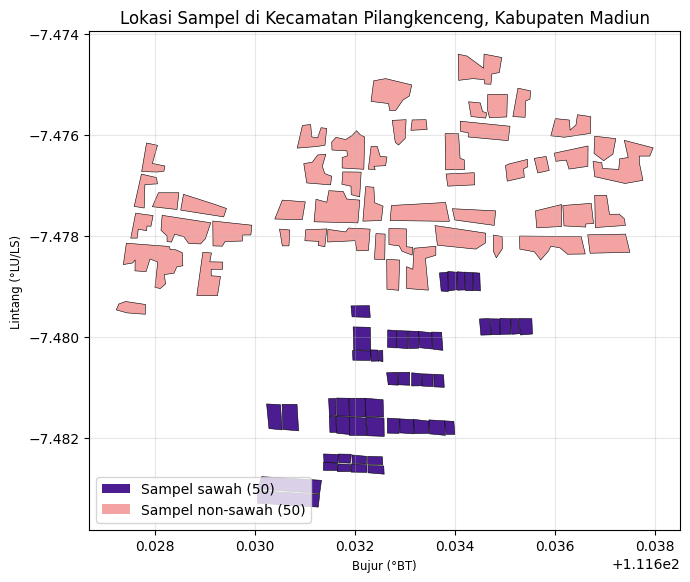

In [16]:
BATAS_FILE = BASE_DIR / "batas_kecamatan_pilangkenceng.geojson"   # hapus berkas ini untuk mengunduh ulang
OUT_BATAS_PNG = BASE_DIR / "peta_batas_pilangkenceng.png"

# Satu titik di dalam tiap poligon sampel, dipakai untuk memilih/memeriksa batas
titik_sampel = pd.concat([gdf_sawah.geometry, gdf_non.geometry]).representative_point()


def pilih_dari_sampel(cand):
    # Dari beberapa kandidat, pilih yang paling banyak memuat titik sampel
    skor = [int(titik_sampel.within(g).sum()) for g in cand.geometry]
    return cand.iloc[[int(np.argmax(skor))]]


def ambil_batas_nominatim():
    r = requests.get(
        "https://nominatim.openstreetmap.org/search",
        params={"q": f"{KEC_NAMA}, {KAB_NAMA}, {PROV_NAMA}, Indonesia", "format": "jsonv2",
                "polygon_geojson": 1, "limit": 10},
        headers={"User-Agent": "klasifikasi-sawah-sentinel2a/1.0 (penelitian akademik)"},
        timeout=60)
    r.raise_for_status()
    geoms = [shape(h["geojson"]) for h in r.json()
             if h.get("category") == "boundary"
             and h.get("geojson", {}).get("type") in ("Polygon", "MultiPolygon")
             and KAB_NAMA.lower() in h.get("display_name", "").lower()]
    if not geoms:
        raise RuntimeError("poligon batas tidak ditemukan")
    return pilih_dari_sampel(gpd.GeoDataFrame({"nama": KEC_NAMA}, geometry=geoms, crs="EPSG:4326"))


def ambil_batas_geoboundaries():
    meta = requests.get("https://www.geoboundaries.org/api/current/gbOpen/IDN/ADM3/", timeout=60)
    meta.raise_for_status()
    r = requests.get(meta.json()["simplifiedGeometryGeoJSON"], timeout=300)
    r.raise_for_status()
    gdf = gpd.read_file(io.BytesIO(r.content)).to_crs(epsg=4326)
    cand = gdf[gdf["shapeName"].str.strip().str.lower() == KEC_NAMA.lower()]
    if cand.empty:
        raise RuntimeError(f"kecamatan {KEC_NAMA} tidak ditemukan")
    return pilih_dari_sampel(cand.assign(nama=KEC_NAMA)[["nama", "geometry"]])


batas_kec, sumber_batas = None, None
if BATAS_FILE.exists():
    batas_kec = gpd.read_file(BATAS_FILE).to_crs(epsg=4326)
    sumber_batas = f"berkas lokal ({BATAS_FILE.name})"
else:
    for nama_sumber, fungsi in (("OpenStreetMap (Nominatim)", ambil_batas_nominatim),
                                ("geoBoundaries ADM3", ambil_batas_geoboundaries)):
        try:
            batas_kec, sumber_batas = fungsi(), nama_sumber
            batas_kec[["nama", "geometry"]].to_file(BATAS_FILE, driver="GeoJSON")
            break
        except Exception as e:
            log(f"PERINGATAN: batas dari {nama_sumber} gagal ({e}).")

fig, ax = plt.subplots(figsize=(7, 7))
handles = []
if batas_kec is None:
    log(f"PERINGATAN: batas kecamatan tidak tersedia. Unggah {BATAS_FILE.name} ke folder kerja "
        "lalu jalankan ulang sel ini. Peta digambar tanpa batas.")
else:
    luas_km2 = batas_kec.to_crs(batas_kec.estimate_utm_crs()).area.sum() / 1e6
    batas_union = batas_kec.geometry.union_all()
    n_dalam = int(titik_sampel.within(batas_union).sum())
    log(f"Batas Kecamatan {KEC_NAMA} dari {sumber_batas} | luas ≈ {luas_km2:.1f} km²")
    log(f"Poligon sampel di dalam batas kecamatan: {n_dalam} dari {len(titik_sampel)}")
    if n_dalam < len(titik_sampel):
        log("CATATAN: sebagian sampel berada di luar batas. Periksa nama kecamatan/kabupaten "
            "(KEC_NAMA, KAB_NAMA) atau posisi digitasi.")
    batas_kec.plot(ax=ax, facecolor="#f4efdf", edgecolor="black", linewidth=1.8)
    handles.append(Patch(facecolor="#f4efdf", edgecolor="black", label=f"Batas Kecamatan {KEC_NAMA}"))

gdf_sawah.plot(ax=ax, facecolor=WARNA["sawah"], edgecolor="black", linewidth=0.4)
gdf_non.plot(ax=ax, facecolor=WARNA["non-sawah"], edgecolor="black", linewidth=0.4)
handles += [Patch(facecolor=WARNA["sawah"], label=f"Sampel sawah ({len(gdf_sawah)})"),
            Patch(facecolor=WARNA["non-sawah"], label=f"Sampel non-sawah ({len(gdf_non)})")]
ax.legend(handles=handles, loc="lower left")
ax.set_title(f"Lokasi Sampel di Kecamatan {KEC_NAMA}, Kabupaten {KAB_NAMA}")
ax.set_xlabel("Bujur (°BT)")
ax.set_ylabel("Lintang (°LU/LS)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_BATAS_PNG, dpi=150)
plt.show()

**Penjelasan kode:** Kode ini mengambil poligon batas Kecamatan Pilangkenceng dari OpenStreetMap (cadangan: geoBoundaries), memilih poligon yang paling banyak memuat sampel apabila ada beberapa kandidat, lalu menyimpannya sebagai `batas_kecamatan_pilangkenceng.geojson`. Luas kecamatan dihitung pada proyeksi UTM yang sesuai, dan jumlah poligon sampel yang berada di dalam batas dicatat ke `LOG`. Berbeda dari versi tanpa penanganan galat, sel ini tetap menampilkan peta sampel (`peta_batas_pilangkenceng.png`) walaupun batas administratif gagal diunduh, dengan peringatan pada log. Jika kedua sumber gagal, unggah sendiri berkas `batas_kecamatan_pilangkenceng.geojson`.

### 9.2 Peta Interaktif Lokasi Sampel

Peta interaktif berlatar citra satelit Esri menampilkan poligon sampel sawah dan non-sawah beserta garis batas kecamatan (bila tersedia). Tampilannya mengikuti peta QGIS Anda (ungu = sawah, merah muda = non-sawah). Peta juga disimpan sebagai berkas HTML.

In [17]:
minx, miny, maxx, maxy = pd.concat([gdf_sawah.geometry, gdf_non.geometry]).total_bounds
m_sampel = folium.Map(
    location=[(miny + maxy) / 2, (minx + maxx) / 2],
    zoom_start=16,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    control_scale=True,
)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m_sampel)

# poligon sampel
for gdf, nama, warna in ((gdf_sawah, "Sawah", WARNA["sawah"]), (gdf_non, "Non-sawah", WARNA["non-sawah"])):
    fg = folium.FeatureGroup(name=f"{nama} ({len(gdf)} poligon)").add_to(m_sampel)
    folium.GeoJson(
        gdf[["kelas", "no", "geometry"]].to_json(),
        style_function=lambda f, c=warna: {"color": "black", "weight": 1, "fillColor": c, "fillOpacity": 0.7},
        highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.9},
        tooltip=folium.GeoJsonTooltip(fields=["kelas", "no"], aliases=["Kelas:", "Polygon ke-"]),
    ).add_to(fg)

# batas kecamatan (bila tersedia)
if batas_kec is not None:
    folium.GeoJson(
        batas_kec[["nama", "geometry"]].to_json(),
        name=f"Batas Kecamatan {KEC_NAMA}",
        style_function=lambda f: {"color": "#FFD400", "weight": 3, "fillOpacity": 0},
    ).add_to(m_sampel)

# kotak legenda
m_sampel.get_root().html.add_child(folium.Element(
    f'''
    <div style="position:fixed; bottom:30px; left:30px; z-index:9999; background:white; padding:10px 14px;
    border:1px solid #888; border-radius:6px; font:13px sans-serif;">
    <b>Peta Sampel Sawah dan Non-Sawah</b><br>
    <b>Kecamatan {KEC_NAMA}, {KAB_NAMA}</b><br>
    <span style="background:{WARNA['non-sawah']}; border:1px solid #555; display:inline-block; width:14px; height:14px;"></span> Non-sawah ({len(gdf_non)} poligon)<br>
    <span style="background:{WARNA['sawah']}; border:1px solid #555; display:inline-block; width:14px; height:14px;"></span> Sawah ({len(gdf_sawah)} poligon)
    </div>
    '''
))

Fullscreen().add_to(m_sampel)
folium.LayerControl(collapsed=False).add_to(m_sampel)
m_sampel.fit_bounds([[miny, minx], [maxy, maxx]], padding=(20, 20))
m_sampel.save(str(BASE_DIR / "peta_sampel_pilangkenceng.html"))

# Tampilkan peta
m_sampel

**Penjelasan kode:** Sel ini membuat peta interaktif dengan basemap Esri World Imagery (sama dengan basemap saat digitasi di QGIS) dan OpenStreetMap sebagai alternatif. Poligon sawah dan non-sawah ditambahkan sebagai dua lapisan terpisah dengan *tooltip* kelas dan nomor poligon, lapisan batas kecamatan ditambahkan hanya jika tersedia, lalu legenda dan kontrol lapisan dipasang. Peta disimpan ke `peta_sampel_pilangkenceng.html`. Apabila peta tidak muncul pada Jupyter, pilih *File -> Trust Notebook* atau buka berkas HTML-nya.

## 10. Penyediaan Citra Sentinel-2A

Fungsi-fungsi berikut hanya dijalankan apabila citra belum tersedia atau `UNDUH_ULANG = True`. Kredensial OAuth Copernicus **tidak ditulis di dalam kode**; kredensial dibaca dari variabel lingkungan `CDSE_CLIENT_ID` dan `CDSE_CLIENT_SECRET`, atau diminta melalui isian tersembunyi.

In [18]:
def get_token():
    from getpass import getpass
    cid = os.environ.get("CDSE_CLIENT_ID") or input("CDSE Client ID: ").strip()
    secret = os.environ.get("CDSE_CLIENT_SECRET") or getpass("CDSE Client Secret: ")
    r = requests.post(TOKEN_URL, data={
        "grant_type": "client_credentials",
        "client_id": cid,
        "client_secret": secret,
    }, timeout=60)
    if r.status_code != 200:
        raise RuntimeError(f"Gagal mengambil token ({r.status_code}): {r.text[:300]}")
    return r.json()["access_token"]


def search_scenes(token):
    body = {
        "collections": ["sentinel-2-l2a"],
        "datetime": f"{START_DATE}T00:00:00Z/{END_DATE}T23:59:59Z",
        "bbox": list(BBOX),
        "limit": 100,
    }
    headers = {"Authorization": f"Bearer {token}"}
    feats = []
    while True:
        r = requests.post(CATALOG_URL, json=body, headers=headers, timeout=120)
        if r.status_code != 200:
            raise RuntimeError(f"Pencarian katalog gagal ({r.status_code}): {r.text[:300]}")
        js = r.json()
        feats += js.get("features", [])
        nxt = js.get("context", {}).get("next")
        if not nxt:
            break
        body["next"] = nxt

    cand = []
    for it in feats:
        p = it.get("properties", {})
        cc = p.get("eo:cloud_cover")
        if cc is None or cc > MAX_CLOUD:
            continue
        if PLATFORM_PREFIX and not it["id"].upper().startswith(PLATFORM_PREFIX):
            continue
        cand.append((cc, p["datetime"], it["id"]))
    cand.sort()
    log(f"Scene ditemukan: {len(feats)} | lolos filter ({PLATFORM_PREFIX or 'semua'}, "
        f"awan <= {MAX_CLOUD}%): {len(cand)}")
    return cand


def utm_epsg(lon, lat):
    return (32700 if lat < 0 else 32600) + int((lon + 180) // 6) + 1


def build_evalscript():
    mask = " || [0,1,3,8,9,10,11].indexOf(s.SCL) >= 0" if MASK_CLOUD else ""
    return ('//VERSION=3\n'
            'function setup() {\n'
            '  return {\n'
            '    input: [{bands: ["B02","B03","B04","B08","B11","B12","SCL","dataMask"]}],\n'
            '    output: {bands: 6, sampleType: "FLOAT32"}\n'
            '  };\n'
            '}\n'
            'function evaluatePixel(s) {\n'
            f'  var bad = (s.dataMask == 0){mask};\n'
            '  if (bad) return [0,0,0,0,0,0];\n'
            '  return [s.B02, s.B03, s.B04, s.B08, s.B11, s.B12];\n'
            '}\n')


def download_scene(token, when):
    epsg = utm_epsg((BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2)
    minx, miny, maxx, maxy = transform_bounds("EPSG:4326", f"EPSG:{epsg}", *BBOX)
    minx, miny = math.floor(minx / 10) * 10, math.floor(miny / 10) * 10
    maxx, maxy = math.ceil(maxx / 10) * 10, math.ceil(maxy / 10) * 10
    w, h = (maxx - minx) // 10, (maxy - miny) // 10
    if w > 2500 or h > 2500:
        raise RuntimeError(f"Area terlalu besar ({w}x{h} piksel, maks 2500). Kecilkan BUFFER_M.")

    t = dt.datetime.fromisoformat(when.replace("Z", "+00:00")).astimezone(dt.timezone.utc)
    fmt = "%Y-%m-%dT%H:%M:%SZ"
    body = {
        "input": {
            "bounds": {
                "bbox": [minx, miny, maxx, maxy],
                "properties": {"crs": f"http://www.opengis.net/def/crs/EPSG/0/{epsg}"},
            },
            "data": [{
                "type": "sentinel-2-l2a",
                "dataFilter": {
                    "timeRange": {"from": (t - dt.timedelta(minutes=1)).strftime(fmt),
                                  "to": (t + dt.timedelta(minutes=1)).strftime(fmt)},
                    "mosaickingOrder": "leastCC",
                },
            }],
        },
        "output": {
            "resx": 10, "resy": 10,
            "responses": [{"identifier": "default", "format": {"type": "image/tiff"}}],
        },
        "evalscript": build_evalscript(),
    }
    r = requests.post(PROCESS_URL, json=body, timeout=300, headers={
        "Authorization": f"Bearer {token}", "Accept": "image/tiff"})
    if r.status_code != 200:
        raise RuntimeError(f"Unduhan gagal ({r.status_code}): {r.text[:400]}")
    return r.content, epsg


def valid_fraction(tif_bytes):
    from rasterio.io import MemoryFile
    with MemoryFile(tif_bytes) as mf, mf.open() as src:
        arr = src.read()
    return float((np.any(arr != 0, axis=0) & np.isfinite(arr).all(axis=0)).mean())


def fetch_sentinel2a():
    token = get_token()
    cand = search_scenes(token)
    if not cand:
        raise RuntimeError(
            f"Tidak ada scene {PLATFORM_PREFIX or ''} dengan awan <= {MAX_CLOUD}% pada "
            f"{START_DATE} s/d {END_DATE}. Perlebar rentang tanggal atau naikkan MAX_CLOUD.")

    best = None
    for cc, when, sid in cand[:MAX_TRIES]:
        data, epsg = download_scene(token, when)
        frac = valid_fraction(data)
        log(f"  {sid[:40]}... | {when} | awan tile {cc:.1f}% | piksel valid {frac:.1%}")
        if best is None or frac > best["frac"]:
            best = dict(frac=frac, data=data, when=when, sid=sid, cc=cc, epsg=epsg)
        if frac >= MIN_VALID:
            break

    TIF_IN.write_bytes(best["data"])
    INFO_TXT.write_text(
        f"Scene    : {best['sid']}\nAkuisisi : {best['when']}\n"
        f"Awan tile: {best['cc']:.1f}%\nPiksel valid di AOI: {best['frac']:.1%}\n"
        f"CRS      : EPSG:{best['epsg']}\nResolusi : 10 m\n"
        f"Band     : {', '.join(BAND_NAMES)} (reflektansi 0-1)\n"
        f"Masking awan (SCL): {MASK_CLOUD}\n", encoding="utf-8")
    log(f"Scene dipakai: {best['sid']} ({best['when']}), valid {best['frac']:.1%}")
    log("Tersimpan:", TIF_IN, "dan", INFO_TXT)

**Penjelasan kode:** Rangkaian fungsi ini mengambil token OAuth, mencari *scene* Sentinel-2A Level-2A pada rentang tanggal dan batas tutupan awan yang ditetapkan, mengunduh area kajian pada resolusi 10 m dalam proyeksi UTM (6 band reflektansi, awan dan bayangan awan di-*mask* dengan band SCL), lalu memilih *scene* dengan fraksi piksel valid terbaik. Hasilnya disimpan sebagai `sentinel2a_aoi.tif` beserta berkas informasi `sentinel2a_aoi_info.txt`.

In [19]:
if TIF_IN.exists() and not UNDUH_ULANG:
    log(f"{TIF_IN.name} sudah ada -> langkah unduh dilewati.")
else:
    fetch_sentinel2a()

CDSE Client ID: sh-e612aa20-e6a3-4c11-b4f4-2b69dd1a6e59
CDSE Client Secret: ··········
Scene ditemukan: 17 | lolos filter (S2A, awan <= 30%): 3


  S2A_MSIL2A_20260802T024151_N0512_R089_T4... | 2026-08-02T03:00:21.701Z | awan tile 5.8% | piksel valid 97.7%
Scene dipakai: S2A_MSIL2A_20260802T024151_N0512_R089_T49MEM_20260802T110511.SAFE (2026-08-02T03:00:21.701Z), valid 97.7%
Tersimpan: /content/sentinel2a_aoi.tif dan /content/sentinel2a_aoi_info.txt


**Penjelasan kode:** Proses unduh hanya dijalankan apabila berkas citra belum ada atau `UNDUH_ULANG = True`. Apabila `sentinel2a_aoi.tif` sudah ada di folder kerja, citra tersebut langsung digunakan.

## 11. Pembacaan Citra dan Pembentukan Fitur

Citra berisi enam band reflektansi (B02, B03, B04, B08, B11, B12). Piksel tanpa data (hasil *masking* awan atau di luar cakupan) ditandai `NaN`. Selanjutnya dibentuk empat indeks spektral sebagai fitur tambahan:

$$NDVI=\frac{B08-B04}{B08+B04},\quad NDWI=\frac{B03-B08}{B03+B08},\quad NDBI=\frac{B11-B08}{B11+B08}$$

$$EVI=2{,}5\times\frac{B08-B04}{B08+6\,B04-7{,}5\,B02+1}$$

In [20]:
with rasterio.open(TIF_IN) as src:
    stack = src.read().astype("float32")
    crs, transform = src.crs, src.transform

if stack.shape[0] != len(BAND_NAMES):
    raise ValueError(f"TIF punya {stack.shape[0]} band, harus {len(BAND_NAMES)} "
                     f"({', '.join(BAND_NAMES)}).")

invalid = np.all(stack == 0, axis=0) | ~np.isfinite(stack).all(axis=0)
stack[:, invalid] = np.nan
H, W = stack.shape[1:]
log(f"Ukuran citra: {W} x {H} piksel | CRS: {crs} | piksel tanpa data: {invalid.mean():.1%}")
B = dict(zip(BAND_NAMES, stack))

Ukuran citra: 418 x 400 piksel | CRS: EPSG:32749 | piksel tanpa data: 2.3%


**Penjelasan kode:** Kode ini membaca seluruh band citra, memastikan jumlah band sesuai (6), menandai piksel bernilai nol di semua band atau tidak hingga sebagai `NaN`, dan menyimpan setiap band dalam kamus `B` agar mudah dipanggil berdasarkan nama.

In [21]:
def nd(a, b):
    return (a - b) / (a + b + 1e-10)


ndvi = nd(B["B08"], B["B04"])
ndwi = nd(B["B03"], B["B08"])
ndbi = nd(B["B11"], B["B08"])
evi = 2.5 * (B["B08"] - B["B04"]) / (B["B08"] + 6 * B["B04"] - 7.5 * B["B02"] + 1)

feats = np.concatenate([stack, np.stack([ndvi, ndwi, ndbi, evi])]).astype("float32")
FEATURE_NAMES = BAND_NAMES + ["NDVI", "NDWI", "NDBI", "EVI"]
F = feats.shape[0]
print("Jumlah fitur:", F, "->", FEATURE_NAMES)

Jumlah fitur: 10 -> ['B02', 'B03', 'B04', 'B08', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI', 'EVI']


**Penjelasan kode:** Fungsi `nd()` menghitung indeks selisih ternormalisasi (konstanta `1e-10` mencegah pembagian dengan nol). Keempat indeks digabung dengan enam band sehingga diperoleh **10 fitur** untuk setiap piksel.

## 12. Rasterisasi Poligon Sampel

Setiap poligon diberi nomor unik dan dikonversi ke raster berukuran sama dengan citra. Hanya piksel di dalam poligon yang memiliki seluruh nilai fitur valid (bebas awan) yang digunakan sebagai sampel.

In [22]:
poly_label, shapes, pid = {}, [], 0
for geoms, kelas in ((geoms_non, 0), (geoms_sawah, 1)):
    for g in geoms:
        pid += 1
        poly_label[pid] = kelas
        shapes.append((transform_geom("EPSG:4326", crs, g), pid))

poly_raster = features.rasterize(shapes, out_shape=(H, W), transform=transform,
                                 fill=0, dtype="int32")
labeled = (poly_raster > 0) & np.isfinite(feats).all(axis=0)
present = np.unique(poly_raster[labeled])

for k, nama in ((0, "non-sawah"), (1, "sawah")):
    ids = [p for p in present if poly_label[p] == k]
    npx = int(np.isin(poly_raster, ids).sum())
    log(f"Kelas {k} ({nama}): {len(ids)} poligon terpakai, {npx} piksel bebas awan")
if len(present) < len(poly_label):
    log(f"PERINGATAN: {len(poly_label) - len(present)} poligon tidak punya piksel valid "
        "(tertutup awan atau di luar citra).")

Kelas 0 (non-sawah): 50 poligon terpakai, 1302 piksel bebas awan
Kelas 1 (sawah): 50 poligon terpakai, 497 piksel bebas awan


**Penjelasan kode:** Poligon diproyeksikan dari EPSG:4326 ke sistem koordinat citra, lalu dirasterisasi dengan nilai piksel berupa nomor poligon. Kamus `poly_label` menyimpan kelas tiap poligon (0 = non-sawah, 1 = sawah). Jumlah poligon dan piksel bebas awan yang terpakai dilaporkan untuk setiap kelas. Poligon sawah pada data ini berukuran kecil (petak-petak persegi panjang), sehingga jumlah piksel sawah kemungkinan jauh lebih sedikit daripada piksel non-sawah.

## 13. Pembagian Data Latih dan Data Uji

Pembagian dilakukan **per poligon**, bukan per piksel. Piksel yang berada dalam satu poligon saling berdekatan dan bernilai mirip sehingga pembagian per piksel dapat menimbulkan kebocoran data spasial (*spatial data leakage*) dan menghasilkan akurasi yang terlalu optimistis.

In [23]:
rng = np.random.default_rng(SEED)
train_ids = []
for k in (0, 1):
    ids = [p for p in present if poly_label[p] == k]
    rng.shuffle(ids)
    train_ids += ids[:max(1, int(round(len(ids) * TRAIN_FRAC)))]

m_train = labeled & np.isin(poly_raster, train_ids)
m_test = labeled & ~m_train
lab_map = np.zeros(poly_raster.max() + 1, dtype="uint8")
for p, k in poly_label.items():
    lab_map[p] = k

X_train, y_train = feats[:, m_train].T, lab_map[poly_raster[m_train]]
X_test, y_test = feats[:, m_test].T, lab_map[poly_raster[m_test]]
log(f"Poligon training: {len(train_ids)} | testing: {len(present) - len(train_ids)}")
log(f"Piksel training: {len(y_train)} | testing: {len(y_test)}")

Poligon training: 70 | testing: 30
Piksel training: 1247 | testing: 552


**Penjelasan kode:** Untuk setiap kelas, poligon diacak lalu 70% dialokasikan sebagai data latih dan sisanya sebagai data uji. Piksel pada poligon latih membentuk `X_train` dan `y_train`, sedangkan piksel pada poligon uji membentuk `X_test` dan `y_test`.

## 14. Pelatihan Model dan Evaluasi

Model Random Forest dengan 200 pohon dilatih menggunakan data latih, kemudian dievaluasi pada data uji menggunakan *confusion matrix*, *overall accuracy*, koefisien Kappa, serta presisi, *recall*, dan *F1-score* per kelas.

In [24]:
rf = RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
pred_test = rf.predict(X_test)

log("\nConfusion matrix (baris=aktual, kolom=prediksi; urutan 0=non-sawah, 1=sawah):")
log(confusion_matrix(y_test, pred_test, labels=[0, 1]))
log(f"Overall Accuracy : {accuracy_score(y_test, pred_test):.4f}")
log(f"Kappa            : {cohen_kappa_score(y_test, pred_test):.4f}")
log(classification_report(y_test, pred_test, labels=[0, 1],
                          target_names=["non-sawah", "sawah"], digits=3))
log("Kepentingan fitur:")
for n, v in sorted(zip(FEATURE_NAMES, rf.feature_importances_), key=lambda x: -x[1]):
    log(f"  {n:5s} {v:.3f}")


Confusion matrix (baris=aktual, kolom=prediksi; urutan 0=non-sawah, 1=sawah):
[[382   0]
 [  0 170]]
Overall Accuracy : 1.0000
Kappa            : 1.0000
              precision    recall  f1-score   support

   non-sawah      1.000     1.000     1.000       382
       sawah      1.000     1.000     1.000       170

    accuracy                          1.000       552
   macro avg      1.000     1.000     1.000       552
weighted avg      1.000     1.000     1.000       552

Kepentingan fitur:
  B11   0.288
  B12   0.275
  NDBI  0.152
  B04   0.149
  B02   0.081
  NDWI  0.019
  NDVI  0.017
  B03   0.017
  B08   0.001
  EVI   0.001


**Penjelasan kode:** Model dilatih dengan data latih dan diuji pada piksel dari poligon yang tidak digunakan saat pelatihan. Keluaran meliputi *confusion matrix*, *overall accuracy*, Kappa, laporan klasifikasi, dan urutan kepentingan fitur berdasarkan `feature_importances_`. Karena jumlah piksel kedua kelas bisa tidak seimbang, perhatikan *precision*, *recall*, dan F1 per kelas, bukan hanya akurasi keseluruhan.

## 15. Klasifikasi Seluruh Citra dan Penghitungan Luas

Akurasi pada bagian 14 berasal dari data uji. Untuk menghasilkan peta, model akhir dilatih ulang menggunakan **seluruh** sampel agar memanfaatkan semua informasi yang tersedia, kemudian diterapkan pada setiap piksel citra yang valid. Piksel tanpa data diberi nilai 255.

In [25]:
rf_final = RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=-1)
rf_final.fit(feats[:, labeled].T, lab_map[poly_raster[labeled]])

flat = feats.reshape(F, -1).T
ok = np.isfinite(flat).all(axis=1)
pred = np.full(flat.shape[0], 255, dtype="uint8")
pred[ok] = rf_final.predict(flat[ok]).astype("uint8")
classified = pred.reshape(H, W)

if crs.is_projected:
    px_area = abs(transform.a * transform.e)
    log(f"\nLuas sawah    : {(classified == 1).sum() * px_area / 10000:.1f} ha")
    log(f"Luas non-sawah: {(classified == 0).sum() * px_area / 10000:.1f} ha")


Luas sawah    : 862.2 ha
Luas non-sawah: 771.9 ha


**Penjelasan kode:** Model akhir dilatih dengan seluruh piksel sampel, lalu memprediksi semua piksel valid pada citra. Luas tiap kelas dihitung dari jumlah piksel dikalikan luas satu piksel (100 m² untuk resolusi 10 m) dan dikonversi ke hektare.

## 16. Penyimpanan dan Visualisasi Hasil

Hasil klasifikasi disimpan sebagai GeoTIFF satu band lengkap dengan *colormap* (merah = non-sawah, hijau = sawah), kemudian ditampilkan berdampingan dengan citra komposit warna asli (RGB).

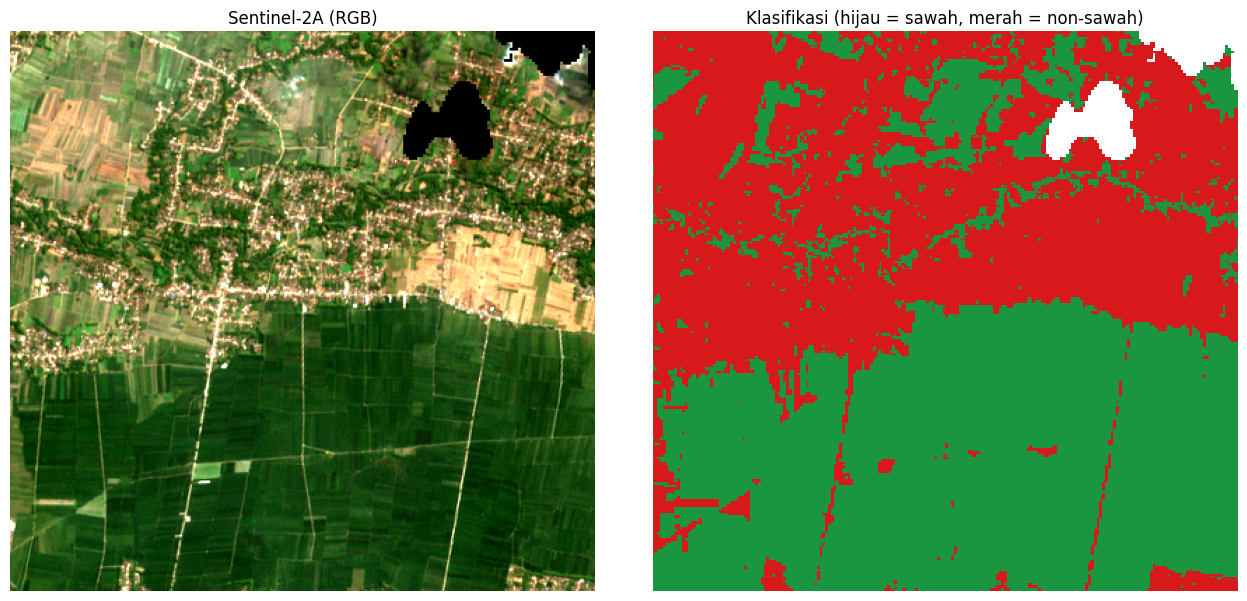


--- DISTRIBUSI KLASIFIKASI WILAYAH ---
 Sawah     : 52.76% (862.21 hektar)
 Non-Sawah : 47.24% (771.89 hektar)

Selesai. Output:
  GeoTIFF  : /content/klasifikasi_sawah_s2a.tif
  Pratinjau: /content/peta_klasifikasi.png
  Evaluasi : /content/hasil_evaluasi.txt


In [26]:
# --- HITUNG PERSENTASE DAN LUAS SAWAH VS NON-SAWAH ---
valid_pixels = classified[classified != 255]
total_valid = len(valid_pixels)

count_sawah = int(np.sum(valid_pixels == 1))
count_nonsawah = int(np.sum(valid_pixels == 0))

pct_sawah = count_sawah / total_valid * 100
pct_nonsawah = count_nonsawah / total_valid * 100

# Estimasi luas (resolusi piksel Sentinel-2 = 10 x 10 m = 100 m2 per piksel)
luas_sawah_ha = count_sawah * 100 / 10000
luas_nonsawah_ha = count_nonsawah * 100 / 10000

# Catat ke LOG agar masuk ke file teks evaluasi
LOG.append(f"Total Piksel Valid: {total_valid}")
LOG.append(f"Sawah     : {pct_sawah:.2f}% ({count_sawah} piksel / {luas_sawah_ha:.2f} hektar)")
LOG.append(f"Non-Sawah : {pct_nonsawah:.2f}% ({count_nonsawah} piksel / {luas_nonsawah_ha:.2f} hektar)")

with rasterio.open(OUT_TIF, "w", driver="GTiff", height=H, width=W, count=1,
                   dtype="uint8", crs=crs, transform=transform,
                   nodata=255, compress="lzw") as dst:
    dst.write(classified, 1)
    dst.set_band_description(1, "kelas (1=sawah, 0=non-sawah)")
    dst.write_colormap(1, {0: (215, 25, 28, 255), 1: (26, 150, 65, 255),
                           255: (0, 0, 0, 0)})

rgb = np.dstack([B["B04"], B["B03"], B["B02"]])
lo, hi = np.nanpercentile(rgb, 2), np.nanpercentile(rgb, 98)
rgb = np.nan_to_num(np.clip((rgb - lo) / (hi - lo + 1e-10), 0, 1))

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].imshow(rgb)
ax[0].set_title("Sentinel-2A (RGB)")
ax[1].imshow(np.ma.masked_equal(classified, 255),
             cmap=ListedColormap(["#d7191c", "#1a9641"]), vmin=0, vmax=1,
             interpolation="nearest")
ax[1].set_title("Klasifikasi (hijau = sawah, merah = non-sawah)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=150)
plt.show()

OUT_TXT.write_text("\n".join(str(s) for s in LOG), encoding="utf-8")

print("\n--- DISTRIBUSI KLASIFIKASI WILAYAH ---")
print(f" Sawah     : {pct_sawah:.2f}% ({luas_sawah_ha:.2f} hektar)")
print(f" Non-Sawah : {pct_nonsawah:.2f}% ({luas_nonsawah_ha:.2f} hektar)")
print("\nSelesai. Output:")
print("  GeoTIFF  :", OUT_TIF)
print("  Pratinjau:", OUT_PNG)
print("  Evaluasi :", OUT_TXT)

**Penjelasan kode:** Kode ini menghitung persentase dan luas masing-masing kelas, menulis hasil klasifikasi ke `klasifikasi_sawah_s2a.tif` (kompresi LZW, nilai 255 sebagai *nodata*), membentuk citra RGB dari B04, B03, dan B02 dengan peregangan kontras persentil 2-98, menampilkan serta menyimpan peta `peta_klasifikasi.png`, dan menulis seluruh catatan `LOG` ke `hasil_evaluasi.txt`.
